<a href="https://colab.research.google.com/github/bvffer/30-days-of-sql/blob/main/notebook9fa7cf0906.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
sukhmanibedi_cars4u_path = kagglehub.dataset_download('sukhmanibedi/cars4u')

print('Data source import complete.')

# Cars4U Used Cars. Price Prediction

The goal is to clean the used-car dataset, explore it, and build a **Multiple Linear Regression** model to predict car prices in **USD**.

All prices used in the analysis, charts, and model evaluation are shown in USD. A fixed conversion factor is applied before analysis. The conversion is not an inflation adjustment.

The notebook distinguishes `kilometers_driven` (total distance travelled) from `fuel_efficiency_kmpl` (kilometres per litre of fuel).

**Main steps:** load data → clean data → review mileage outliers → explore the data → check skewness and log transformation → prepare features → train the model → evaluate the model.


---
# Part 1: Data Cleaning

## 1. Import libraries and load the data

In [ ]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

paths = glob.glob("/kaggle/input/**/used_cars_data.csv", recursive=True)
if not paths:
    paths = glob.glob("used_cars_data*.csv")
if not paths:
    raise FileNotFoundError("Place used_cars_data.csv in the notebook folder or add it to Kaggle.")

path = paths[0]
df = pd.read_csv(path, index_col=0)
df.columns = df.columns.str.strip().str.lower()

print("Data shape:", df.shape)
df.info()


Data shape: (7253, 13)
<class 'pandas.core.frame.DataFrame'>
Index: 7253 entries, 0 to 7252
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               7253 non-null   object 
 1   location           7253 non-null   object 
 2   year               7253 non-null   int64  
 3   kilometers_driven  7253 non-null   int64  
 4   fuel_type          7253 non-null   object 
 5   transmission       7253 non-null   object 
 6   owner_type         7253 non-null   object 
 7   mileage            7251 non-null   object 
 8   engine             7207 non-null   object 
 9   power              7207 non-null   object 
 10  seats              7200 non-null   float64
 11  new_price          1006 non-null   object 
 12  price              6019 non-null   float64
dtypes: float64(2), int64(2), object(9)
memory usage: 793.3+ KB


## 2. Check missing values

We check missing values before cleaning. The `new_price` column has a high percentage of missing values, so we remove it instead of filling most of its values.

In [ ]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

new_price    6247
price        1234
seats          53
engine         46
power          46
mileage         2
dtype: int64


In [ ]:
df.drop(columns=["new_price"], inplace=True)

## 3. Convert prices to USD

We apply the same fixed conversion factor to every row. The original price column is removed, so the working dataset uses `price_usd`.

In [ ]:
USD_PER_PRICE_UNIT = 1069.80

df["price_usd"] = pd.to_numeric(df["price"], errors="coerce") * USD_PER_PRICE_UNIT
df.drop(columns=["price"], inplace=True)

print(df[["price_usd"]].describe().round(2))

       price_usd
count    6019.00
mean    10141.14
std     11968.83
min       470.71
25%      3744.30
50%      6033.67
75%     10644.51
max    171168.00


## 4. Remove duplicates and clean text

We remove extra spaces and make text values consistent first. Then we remove duplicate rows. Doing this order also catches rows that only differ by text capitalization or spaces.


In [ ]:
text_cols = ["name", "location", "fuel_type", "transmission", "owner_type"]

for col in text_cols:
    df[col] = df[col].str.strip().str.title()

before = len(df)
df.drop_duplicates(inplace=True)
print("Duplicate rows removed:", before - len(df))
print("Data shape:", df.shape)


Duplicate rows removed: 3
Data shape: (7250, 12)


## 5. Convert text columns to numbers

Some columns contain numbers together with units. We extract the numeric values.

The source `mileage` column mixes `kmpl` (kilometres per litre) and `km/kg` (kilometres per kilogram). These units are not interchangeable, so we keep only `kmpl` values in `fuel_efficiency_kmpl`. Other values become missing and are handled later by the model's median imputer.


In [ ]:
fuel_efficiency = df["mileage"].str.lower().str.extract(r"([0-9]*\.?[0-9]+)\s*kmpl", expand=False)
df["fuel_efficiency_kmpl"] = pd.to_numeric(fuel_efficiency, errors="coerce")
df.drop(columns=["mileage"], inplace=True)

for col in ["engine", "power"]:
    df[col] = pd.to_numeric(df[col].str.split().str[0], errors="coerce")

print(df[["fuel_efficiency_kmpl", "engine", "power"]].head())
print("Missing fuel-efficiency values:", df["fuel_efficiency_kmpl"].isna().sum())


       fuel_efficiency_kmpl  engine   power
S.No.                                      
0                       NaN   998.0   58.16
1                     19.67  1582.0  126.20
2                     18.20  1199.0   88.70
3                     20.77  1248.0   88.76
4                     15.20  1968.0  140.80
Missing fuel-efficiency values: 76


## 6. Create useful features

- `brand`: the car manufacturer from the name. `Land Rover` is kept as one brand.
- `age_of_car`: the car's age, using 2021 because that is the dataset year.

We remove `name` and `year` after creating these features. `new_price` was already removed because most of its values were missing.


In [ ]:
df["brand"] = df["name"].str.split().str[0]
df.loc[df["name"].str.startswith("Land Rover"), "brand"] = "Land Rover"

current_year = 2021
df["age_of_car"] = current_year - df["year"]

df.drop(columns=["name", "year"], inplace=True)

df.head()


,location,kilometers_driven,fuel_type,transmission,owner_type,engine,power,seats,price_usd,fuel_efficiency_kmpl,brand,age_of_car
S.No.,,,,,,,,,,,,
0,Mumbai,72000,Cng,Manual,First,998.0,58.16,5.0,1872.150,NaN,Maruti,11
1,Pune,41000,Diesel,Manual,First,1582.0,126.20,5.0,13372.500,19.67,Hyundai,6
2,Chennai,46000,Petrol,Manual,First,1199.0,88.70,5.0,4814.100,18.20,Honda,10
3,Chennai,87000,Diesel,Manual,First,1248.0,88.76,7.0,6418.800,20.77,Maruti,9
4,Coimbatore,40670,Diesel,Automatic,Second,1968.0,140.80,5.0,18978.252,15.20,Audi,8


## 7. Handle invalid values

Zero or negative values are not valid for fuel efficiency, engine, power, or seats. We mark them as missing. We also remove rows without a valid target price because the model cannot learn from a missing price.


In [ ]:
for col in ["fuel_efficiency_kmpl", "engine", "power", "seats"]:
    df.loc[df[col] <= 0, col] = np.nan

df.loc[df["age_of_car"] < 0, "age_of_car"] = np.nan

df.dropna(subset=["price_usd"], inplace=True)
df = df[df["price_usd"] > 0]

print("Data shape:", df.shape)
print("Missing values:")
print(df.isna().sum())

Data shape: (6018, 12)
Missing values:
location                  0
kilometers_driven         0
fuel_type                 0
transmission              0
owner_type                0
engine                   36
power                   143
seats                    43
price_usd                 0
fuel_efficiency_kmpl    136
brand                     0
age_of_car                0
dtype: int64


## 8. Check and handle outliers

The IQR rule helps us find unusual values:

- `IQR = Q3 - Q1`
- Upper limit = `Q3 + 3 * IQR`

An unusual value is not always an error. In this dataset, high prices, large engines, and high power can belong to real luxury or performance cars, so we keep those records.

For `kilometers_driven`, the IQR rule flags unusually high readings. We inspect them and remove only values above 500,000 km, which are likely data-entry errors. This avoids removing genuine expensive cars just because their prices are far from the average.


In [ ]:
q1 = df["kilometers_driven"].quantile(0.25)
q3 = df["kilometers_driven"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 3 * iqr

print("IQR upper limit:", round(upper_limit, 0), "km")
print("Possible high-mileage outliers:", (df["kilometers_driven"] > upper_limit).sum())

# Review the highest mileage readings before removing clear data errors.
high_km = df[df["kilometers_driven"] > upper_limit]
display(high_km[["brand", "kilometers_driven", "price_usd"]].sort_values(
    "kilometers_driven", ascending=False
).head(10))

# Remove only the clearly implausible mileage readings.
before = len(df)
df = df[df["kilometers_driven"] <= 500_000].copy()

print("Rows removed:", before - len(df))
print("Rows remaining:", len(df))


IQR upper limit: 190000.0 km
Possible high-mileage outliers: 45


,brand,kilometers_driven,price_usd
S.No.,,,
2328,Bmw,6500000,69537.00
340,Skoda,775000,8023.50
1860,Volkswagen,720000,6311.82
358,Hyundai,620000,2888.46
2823,Volkswagen,480000,13907.40
3092,Honda,480000,5349.00
4491,Hyundai,445000,4760.61
3649,Tata,300000,1069.80
1528,Toyota,299322,4279.20


Rows removed: 4
Rows remaining: 6014


## 9. Final cleaning check

We review the cleaned data before starting the analysis.


Data shape: (6014, 12)
Total missing values: 358


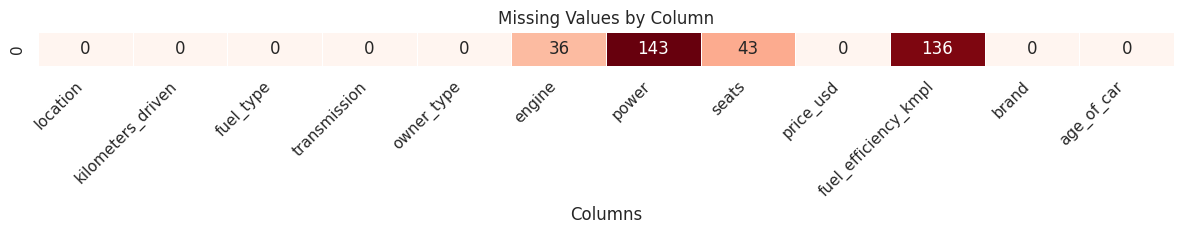

,location,kilometers_driven,fuel_type,transmission,owner_type,engine,power,seats,price_usd,fuel_efficiency_kmpl,brand,age_of_car
S.No.,,,,,,,,,,,,
0,Mumbai,72000,Cng,Manual,First,998.0,58.16,5.0,1872.150,NaN,Maruti,11.0
1,Pune,41000,Diesel,Manual,First,1582.0,126.20,5.0,13372.500,19.67,Hyundai,6.0
2,Chennai,46000,Petrol,Manual,First,1199.0,88.70,5.0,4814.100,18.20,Honda,10.0
3,Chennai,87000,Diesel,Manual,First,1248.0,88.76,7.0,6418.800,20.77,Maruti,9.0
4,Coimbatore,40670,Diesel,Automatic,Second,1968.0,140.80,5.0,18978.252,15.20,Audi,8.0


In [ ]:
print("Data shape:", df.shape)
print("Total missing values:", df.isna().sum().sum())

missing_values = df.isna().sum().to_frame().T

plt.figure(figsize=(12, 2.5))
sns.heatmap(
    missing_values,
    annot=True,
    fmt="d",
    cmap="Reds",
    cbar=False,
    linewidths=0.5
)

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(df.head())


---
# Part 2: Exploratory Data Analysis (EDA)

EDA helps us understand the data before training the model.

## 10. Summary statistics


In [ ]:
num_cols = ["price_usd", "kilometers_driven", "fuel_efficiency_kmpl", "engine", "power", "seats", "age_of_car"]

print(df[num_cols].describe().round(2))
print("\nTop 10 brands:")
print(df["brand"].value_counts().head(10))

       price_usd  kilometers_driven  fuel_efficiency_kmpl   engine    power  \
count    6014.00            6014.00               5878.00  5978.00  5871.00   
mean    10134.83           57346.05                 18.27  1621.20   113.24   
std     11948.31           34993.25                  4.10   601.21    53.85   
min       470.71             171.00                  6.40    72.00    34.20   
25%      3744.30           34000.00                 15.30  1198.00    75.00   
50%      6033.67           53000.00                 18.19  1493.00    97.70   
75%     10644.51           73000.00                 21.10  1984.00   138.10   
max    171168.00          480000.00                 28.40  5998.00   560.00   

         seats  age_of_car  
count  5971.00     6014.00  
mean      5.28        7.64  
std       0.81        3.27  
min       2.00        2.00  
25%       5.00        5.00  
50%       5.00        7.00  
75%       5.00       10.00  
max      10.00       23.00  

Top 10 brands:
brand
Marut

## 11. Price distribution

The histogram shows how car prices are distributed.


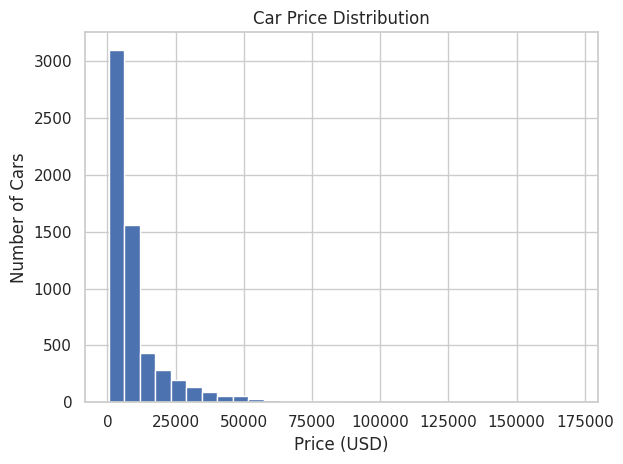

In [ ]:
plt.hist(df["price_usd"], bins=30)
plt.title("Car Price Distribution")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()


## 12. Price skewness and log transformation

Skewness shows whether a distribution is balanced or has a long tail. `np.log1p()` can reduce right skewness. We compare the original and transformed distributions.

The transformed values are used only for this EDA comparison. The model continues to predict the original `price_usd` values.


Skewness before: 3.34
Skewness after : 0.42


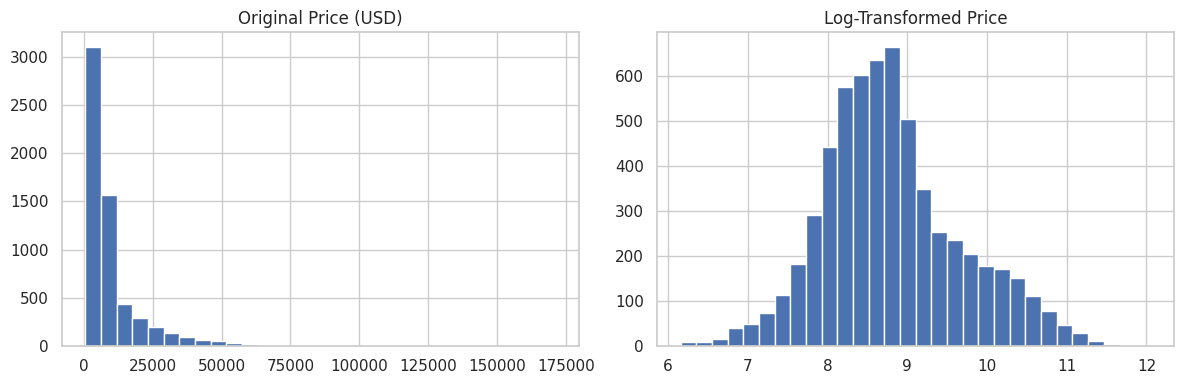

In [ ]:
price_log = np.log1p(df["price_usd"])

print("Skewness before:", round(df["price_usd"].skew(), 2))
print("Skewness after :", round(price_log.skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["price_usd"], bins=30)
axes[0].set_title("Original Price (USD)")

axes[1].hist(price_log, bins=30)
axes[1].set_title("Log-Transformed Price")

plt.tight_layout()
plt.show()


## 13. Numeric feature distributions

These histograms show the distribution of six numerical features:

- `kilometers_driven`: total distance the car has travelled, in kilometres (km).
- `fuel_efficiency_kmpl`: distance travelled per litre of fuel, in kilometres per litre (km/L).
- `engine`: engine size, in cubic centimetres (CC).
- `power`: engine power, in brake horsepower (bhp).
- `seats`: number of seats.
- `age_of_car`: car age, in years.

`kilometers_driven` is total distance. `fuel_efficiency_kmpl` is fuel economy. They measure different things.


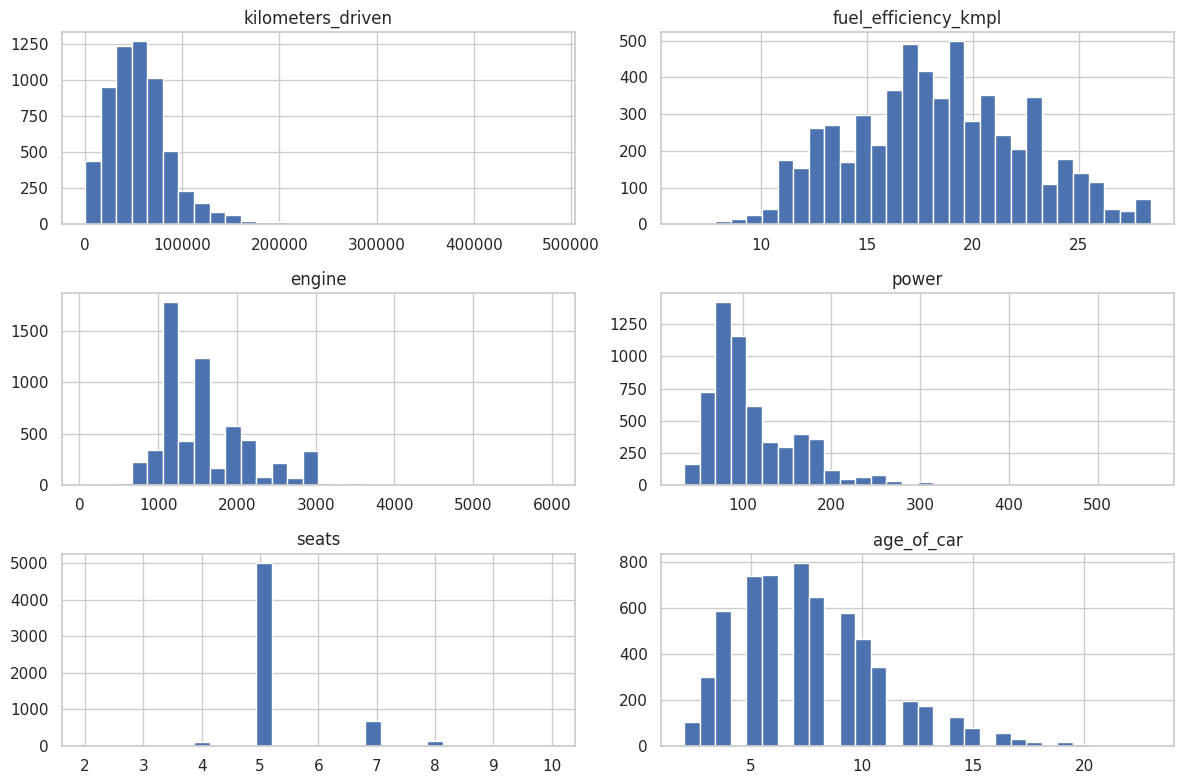

In [ ]:
hist_cols = [
    "kilometers_driven",
    "fuel_efficiency_kmpl",
    "engine",
    "power",
    "seats",
    "age_of_car"
]

df[hist_cols].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()


## 14. Categorical features

Count plots show the most common values in the categorical columns.


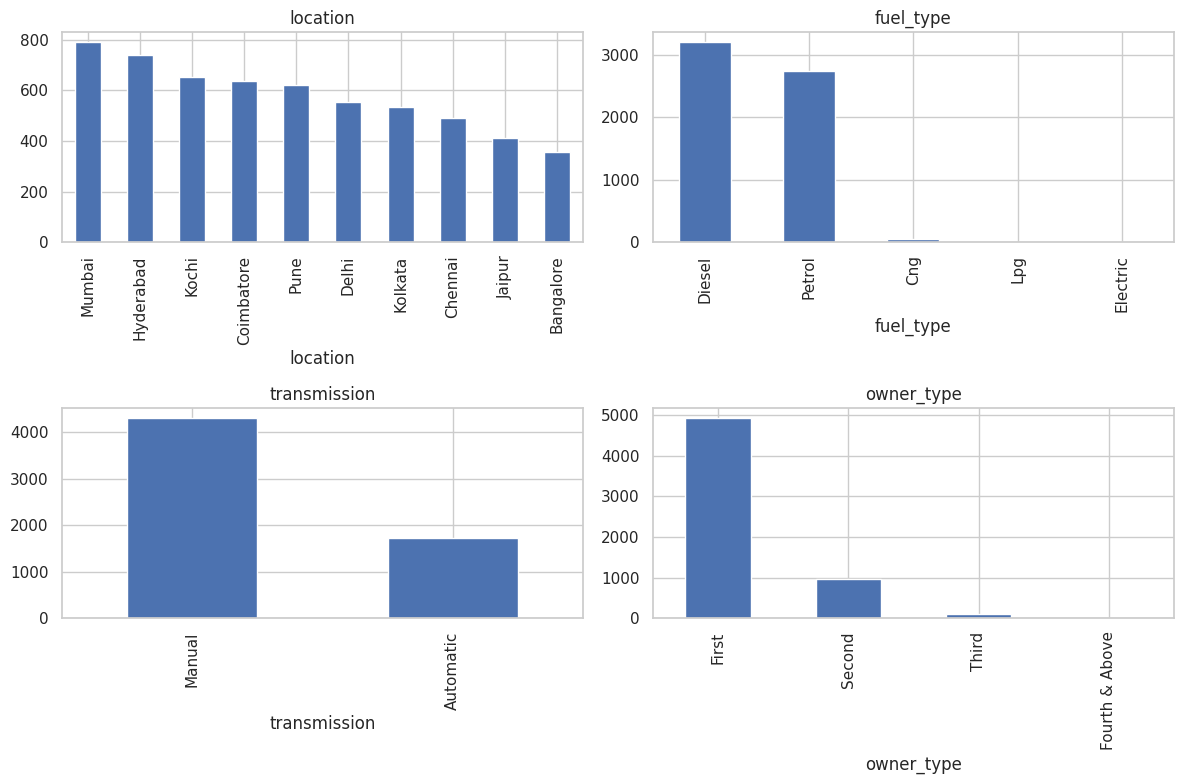

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(["location", "fuel_type", "transmission", "owner_type"], axes.ravel()):
    df[col].value_counts().head(10).plot(kind="bar", ax=ax, title=col)

plt.tight_layout()
plt.show()

## 15. Price vs. numeric features

Scatter plots help us see how numerical features relate to car prices.


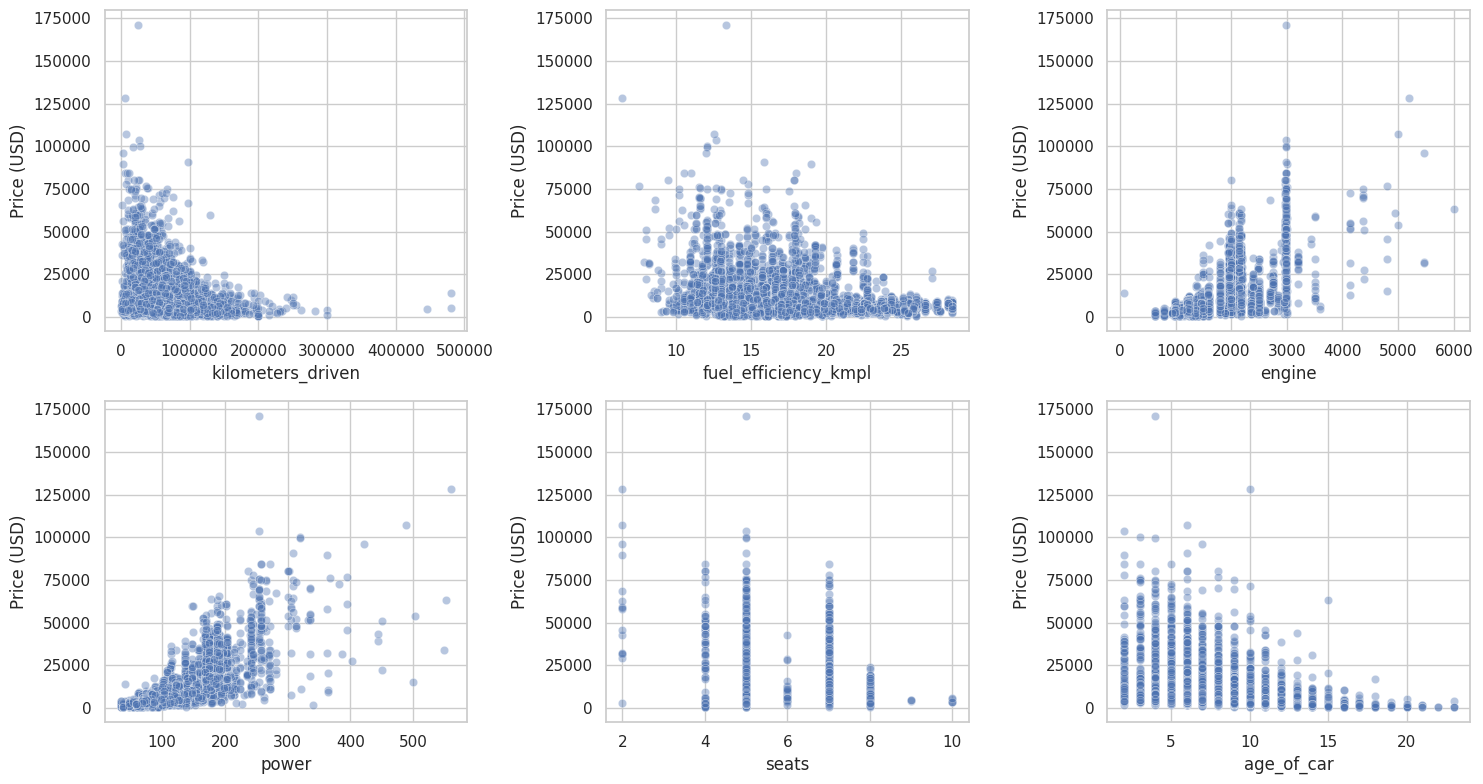

In [ ]:
scatter_cols = [
    "kilometers_driven",
    "fuel_efficiency_kmpl",
    "engine",
    "power",
    "seats",
    "age_of_car"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, ax in zip(scatter_cols, axes.ravel()):
    sns.scatterplot(data=df, x=col, y="price_usd", alpha=0.4, ax=ax)
    ax.set_ylabel("Price (USD)")

plt.tight_layout()
plt.show()


## 16. Price vs. categorical features

Boxplots compare price distributions across categories.


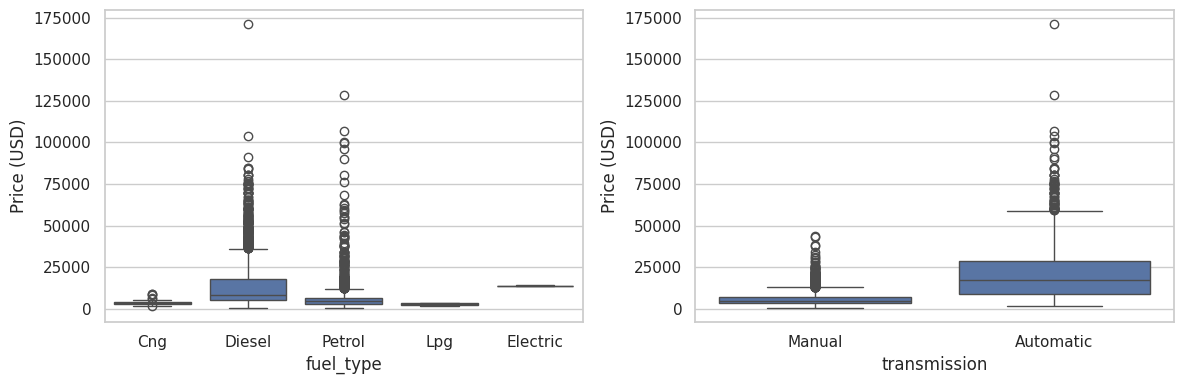

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="fuel_type", y="price_usd", ax=axes[0])
sns.boxplot(data=df, x="transmission", y="price_usd", ax=axes[1])

axes[0].set_ylabel("Price (USD)")
axes[1].set_ylabel("Price (USD)")
plt.tight_layout()
plt.show()

## 17. Correlation

Correlation measures the linear relationship between numerical columns. It ranges from -1 to +1. Correlation does not prove that one feature causes another.

In this dataset, `engine` and `power` are strongly correlated. They describe related vehicle properties, so their individual model coefficients may be less stable. We keep both because they provide different information about the car.


                      price_usd  kilometers_driven  fuel_efficiency_kmpl  \
price_usd                  1.00              -0.18                 -0.33   
kilometers_driven         -0.18               1.00                 -0.16   
fuel_efficiency_kmpl      -0.33              -0.16                  1.00   
engine                     0.66               0.17                 -0.65   
power                      0.77               0.00                 -0.55   
seats                      0.05               0.23                 -0.35   
age_of_car                -0.30               0.48                 -0.30   

                      engine  power  seats  age_of_car  
price_usd               0.66   0.77   0.05       -0.30  
kilometers_driven       0.17   0.00   0.23        0.48  
fuel_efficiency_kmpl   -0.65  -0.55  -0.35       -0.30  
engine                  1.00   0.87   0.40        0.05  
power                   0.87   1.00   0.10       -0.01  
seats                   0.40   0.10   1.00       

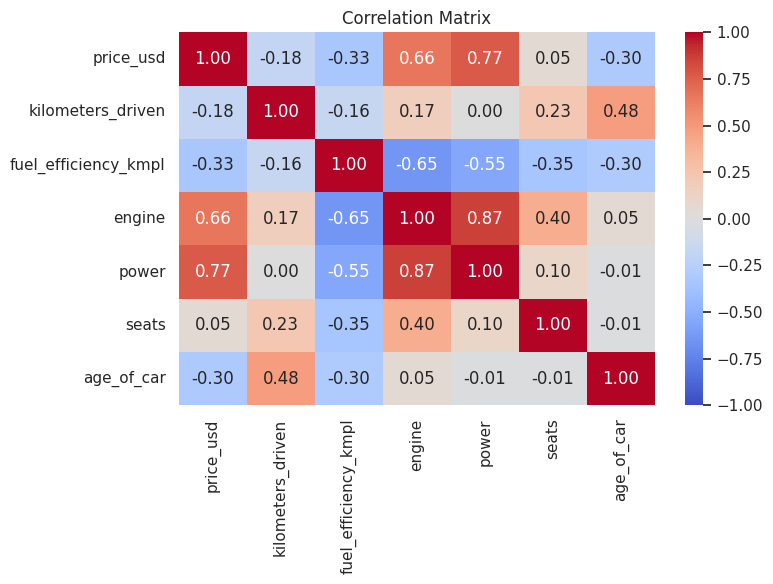

In [ ]:
corr = df[num_cols].corr()
print(corr.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


---
# Part 3: Preparing the Data for Machine Learning

We separate the target from the features, encode categorical values, and scale numerical values. We use `ColumnTransformer` to apply the correct preprocessing to each type of column.

## 18. Features (X) and target (y)

- `X` contains the information used to predict the price.
- `y` contains the price we want to predict.


In [ ]:
X = df.drop(columns=["price_usd"])
y = df["price_usd"]

print("Features:", X.columns.tolist())
print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['location', 'kilometers_driven', 'fuel_type', 'transmission', 'owner_type', 'engine', 'power', 'seats', 'fuel_efficiency_kmpl', 'brand', 'age_of_car']
X shape: (6014, 11)
y shape: (6014,)


## 19. Select numerical and categorical features


In [ ]:
num_features = ["kilometers_driven", "fuel_efficiency_kmpl", "engine", "power", "seats", "age_of_car"]
cat_features = ["brand", "location", "fuel_type", "transmission", "owner_type"]

## 20. Build preprocessing pipelines

- Numerical columns: fill missing values with the median, then apply `StandardScaler`.
- Categorical columns: fill missing values with the most frequent value, then apply `OneHotEncoder`.
- `handle_unknown="ignore"` lets the model process a category that was not present in the training set. A warning may appear, but this is not an error. The unfamiliar category is encoded as all zeros.
- `drop="first"` removes one category from each feature to avoid redundant dummy columns.
- Fuel-efficiency values recorded in `km/kg` are treated as missing because they cannot be directly labelled as `km/L`.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", cat_pipeline, cat_features)
])


## 21. Train / test split

We use 80% of the data for training and 20% for testing. The test data is kept separate to evaluate the model on records it did not train on.


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4811, 11)
Testing data: (1203, 11)


---
# Part 4: Model Building

## 22. Train the Linear Regression model

The pipeline applies preprocessing and then trains the Linear Regression model.


In [ ]:
from sklearn.linear_model import LinearRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['kilometers_driven',
                                                   'fuel_efficiency_kmpl',
                                                   'engine', 'power', 'seats',
                                                   'age_of_car']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['brand', 'location',
                                                   'fuel_type', 'transmission',
                                                   'owner_type'])])),
                ('regressor', LinearRegression())])

## 23. Coefficients and intercept

The coefficients show how each processed feature contributes to the model. The intercept is the model's starting value. Numerical coefficients are based on scaled features because we use `StandardScaler`.


In [ ]:
# Display the coefficients and intercept
print("coefficients : ", model.named_steps["regressor"].coef_)
print("intercept : ", model.named_steps["regressor"].intercept_)

coefficients :  [ -1099.64513553   -313.0197735    1465.43900266   4598.69693571
    170.27150144  -2979.31062623   -842.99117606 -10092.89904824
 -12310.52903583  -9949.41385078 -12874.14745415  -9560.06860611
 -10627.94016696  -9815.99353722 -14544.38800377   8881.39808706
  -8654.61770935  64228.69684598  14594.40468994 -12645.88243949
  -8537.69245963    597.55630059   5126.04611279  -8682.24519854
  -9947.84651358  10471.22191993 -10466.76867443 -10131.32787264
  -4099.14720769 -10705.58033418  -8291.46241299 -10491.11826039
  -6761.80760218   1849.58959824   1295.4561964    2158.24003402
   -878.21163523   1831.99230321   1019.75725243   -116.77184655
  -1465.02262907  -1116.14715286    549.54913407    628.8866818
  15363.34504098   1943.73680898   -501.88553472    315.01530294
   1638.26445587   -491.91552297    940.19380213]
intercept :  17256.69741463179


## 24. Model performance

We use these metrics to evaluate the model:

- **MSE:** average squared prediction error, in USD².
- **RMSE:** square root of MSE, in USD.
- **MAE:** average absolute prediction error, in USD.
- **R²:** the proportion of price variation explained by the model. It is not classification accuracy.

Linear Regression can sometimes predict a negative price. Since a car cannot have a negative price, we set negative predictions to zero before calculating the metrics.


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Predict car prices
y_pred = model.predict(X_test)

# Car prices cannot be negative
print("Negative predictions:", (y_pred < 0).sum())
y_pred = np.maximum(y_pred, 0)

# Calculate performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE =", round(mse, 2))
print("RMSE =", round(rmse, 2), "USD")
print("MAE =", round(mae, 2), "USD")
print("R2 =", round(r2, 3))
print("Variance explained =", round(r2 * 100, 1), "%")


Negative predictions: 96
MSE = 24058512.09
RMSE = 4904.95 USD
MAE = 2841.38 USD
R2 = 0.821
Variance explained = 82.1 %


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## 25. Actual vs. predicted prices


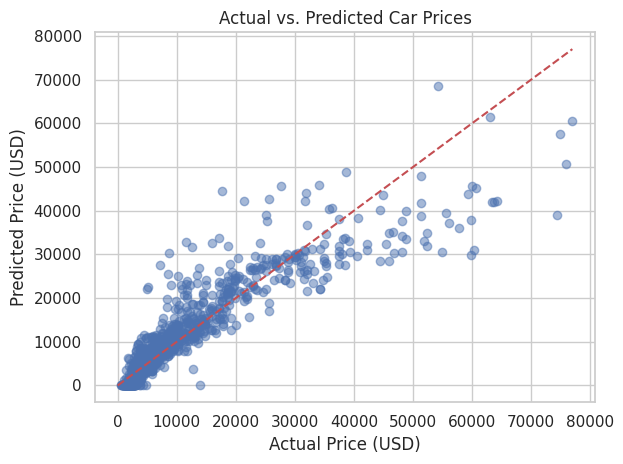

In [ ]:
plt.scatter(y_test, y_pred, alpha=0.5)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())
plt.plot([minimum, maximum], [minimum, maximum], "r--")

plt.title("Actual vs. Predicted Car Prices")
plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.tight_layout()
plt.show()


# **Decision Tree Classification**

goal : classify a used car into Budget, Mid-range, Premium, or Luxury.

steps:
1. prepare target variable (y)
2. select features
3. split dataset
4. preprocess features
5. choose and train classifier
6. make prediction
7. evalute model preformance

# prepare target variable (y)

In [ ]:
# Price boundaries come from the TRAINING set only, so no test information leaks in
price_quantiles = y_train.quantile([0.25, 0.50, 0.75])

price_bins = [
    -np.inf,
    price_quantiles[0.25],   # Budget upper limit
    price_quantiles[0.50],   # Mid-range upper limit
    price_quantiles[0.75],   # Premium upper limit
    np.inf
]

# Four price categories (needs 5 bin edges)
price_labels = ["Budget", "Mid-range", "Premium", "Luxury"]

# Create categorical target for the same train/test split used above
y_train_class = pd.cut(y_train, bins=price_bins, labels=price_labels)
y_test_class = pd.cut(y_test, bins=price_bins, labels=price_labels)

# Keep a copy on df for reference
df["price_category"] = pd.cut(df["price_usd"], bins=price_bins, labels=price_labels)

print("Bin edges (USD):", [round(float(b), 2) for b in price_bins[1:-1]])
print(y_train_class.value_counts().reindex(price_labels))


Bin edges (USD): [3744.3, 5990.88, 10430.55]
price_usd
Budget       1254
Mid-range    1156
Premium      1203
Luxury       1198
Name: count, dtype: int64


# Preparing the Features (X).

In [ ]:
# Features: drop both the numeric target and the new categorical target (avoids leakage)
X = df.drop(columns=["price_usd", "price_category"])


# Step 3: Prepare preprocessing for Decision Trees

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing
num_pipeline_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
cat_pipeline_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])

# Combine preprocessing
tree_preprocessor = ColumnTransformer([
    ("num", num_pipeline_tree, num_features),
    ("cat", cat_pipeline_tree, cat_features)
])

**Import the classifier**

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=5,
        random_state=42
    ))
])


**Train the model**

In [ ]:
tree_model.fit(X_train, y_train_class)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['kilometers_driven',
                                                   'fuel_efficiency_kmpl',
                                                   'engine', 'power', 'seats',
                                                   'age_of_car']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['brand', 'location',
                                                   'fuel_type', 'transmission',
                                                   'owner_type'])])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=12, min_samples_leaf=5,
                                        min_samples_split=20,
                                        random_state=42))])

**Inspect the trained tree**

In [ ]:
classifier = tree_model.named_steps["classifier"]

print("Tree depth:", classifier.get_depth())
print("Number of leaves:", classifier.get_n_leaves())
print("Classes:", classifier.classes_)

Tree depth: 12
Number of leaves: 241
Classes: ['Budget' 'Luxury' 'Mid-range' 'Premium']


**Make predictions**

In [ ]:
y_pred_class = tree_model.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


**Calculate **accuracy****

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test_class, y_pred_class)

print("Accuracy:", round(accuracy, 4))
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.7955
Accuracy percentage: 79.55 %


**Classification report**

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_class,
    y_pred_class,
    labels=price_labels,
    zero_division=0
))

              precision    recall  f1-score   support

      Budget       0.90      0.83      0.86       310
   Mid-range       0.70      0.66      0.68       283
     Premium       0.68      0.75      0.72       282
      Luxury       0.88      0.91      0.90       328

    accuracy                           0.80      1203
   macro avg       0.79      0.79      0.79      1203
weighted avg       0.80      0.80      0.80      1203



**confusion_matrix**

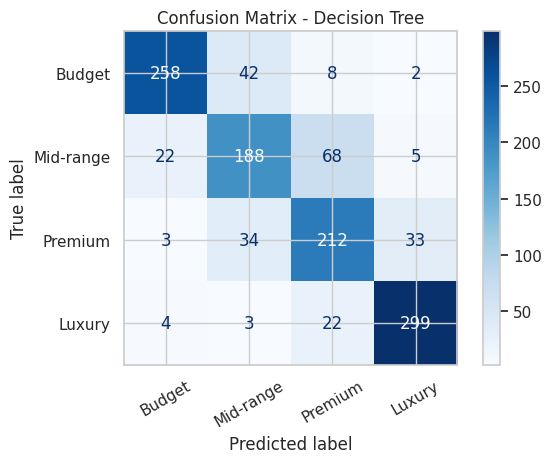

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_class, y_pred_class, labels=price_labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=price_labels)
disp.plot(cmap="Blues", xticks_rotation=30)
plt.title("Confusion Matrix - Decision Tree")
plt.tight_layout()
plt.show()

---
# Summary

1. Cleaned the dataset, standardized text, removed duplicates, and handled invalid values.
2. Converted the target price to USD and created `fuel_efficiency_kmpl`, `brand`, and `age_of_car` features.
3. Used the IQR rule to identify unusual mileage values and removed only implausible readings above 500,000 km. Genuine luxury-car prices and performance values were kept.
4. Explored the data using statistics, histograms, scatter plots, boxplots, and a correlation heatmap.
5. Compared price skewness before and after a log transformation. The model still predicts the original USD price.
6. Used median imputation and `StandardScaler` for numerical features.
7. Used most-frequent imputation and One-Hot Encoding for categorical features.
8. Used `ColumnTransformer` and `Pipeline` to organize preprocessing and model training.
9. Trained a Multiple Linear Regression model, prevented negative price predictions, and evaluated it using MSE, RMSE, MAE, and R².
